# Phase 2 — Probability, distributions, moments, and bivariate analysis

This phase uses the patient-level multimodal dataset produced by Phase 1. The same molecular feature selected in Phase 1 is used throughout. One row represents one patient.

In [3]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import binom

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from project_utils import save_figure

DATA = ROOT / "processed"
FIG = ROOT / "figures" / "phase2"
FIG.mkdir(parents=True, exist_ok=True)
INPUT = DATA / "phase1_patient_level.csv"
if not INPUT.exists():
    raise FileNotFoundError("Run notebooks/phase1.ipynb first; expected processed/phase1_patient_level.csv")
SELECTED_GENE = "A1BG_RNA"  # Must match Phase 1
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

df = pd.read_csv(INPUT)
required = {"patient_id", "age_years", "stage_group", SELECTED_GENE}
missing = required - set(df.columns)
if missing: raise KeyError(f"Missing expected columns: {missing}")
assert df.patient_id.is_unique, "Observations must be unique at patient level."
df[SELECTED_GENE] = pd.to_numeric(df[SELECTED_GENE], errors="coerce")
print("Patient-level input shape:", df.shape)
print("Unique patients:", df.patient_id.nunique())
print("Selected gene:", SELECTED_GENE)

Patient-level input shape: (936, 7)
Unique patients: 936
Selected gene: A1BG_RNA


## 1. Define events and the analysis population

Let \(A\) denote advanced disease (stage III/IV) and \(B\) denote high expression (strictly above the cohort median). The analysis population is complete cases for stage group and expression. Median split is a descriptive dichotomization, not a biological threshold.

In [4]:
analysis = df.dropna(subset=["stage_group", SELECTED_GENE]).copy()
median_expr = analysis[SELECTED_GENE].median()
analysis["A_advanced"] = analysis.stage_group.eq("Advanced")
analysis["B_high_expression"] = analysis[SELECTED_GENE] > median_expr
analysis["A"] = analysis["A_advanced"]
analysis["B"] = analysis["B_high_expression"]
N = len(analysis)
if N == 0: raise ValueError("No complete cases for stage and selected gene.")
print("Complete-case N:", N)
print("Excluded due to missing stage/expression:", len(df)-N)
print("Expression median:", median_expr)

tab = pd.crosstab(analysis["A"], analysis["B"]).reindex(index=[False,True], columns=[False,True], fill_value=0)
tab.index = ["Not advanced", "Advanced"]
tab.columns = ["Not high", "High"]
display(tab)

p_A = analysis.A.mean()
p_B = analysis.B.mean()
p_AB = (analysis.A & analysis.B).mean()
p_B_given_A = analysis.loc[analysis.A, "B"].mean() if analysis.A.any() else np.nan
p_B_given_notA = analysis.loc[~analysis.A, "B"].mean() if (~analysis.A).any() else np.nan
p_A_given_B = analysis.loc[analysis.B, "A"].mean() if analysis.B.any() else np.nan
p_A_given_notB = analysis.loc[~analysis.B, "A"].mean() if (~analysis.B).any() else np.nan
probabilities = pd.Series({
    "P(A)":p_A, "P(B)":p_B, "P(A and B)":p_AB,
    "P(B|A)":p_B_given_A, "P(B|not A)":p_B_given_notA,
    "P(A|B)":p_A_given_B, "P(A|not B)":p_A_given_notB,
})
display(probabilities.to_frame("Probability"))

# Bayes identity check: P(A|B) = P(B|A)P(A)/P(B)
bayes_rhs = p_B_given_A*p_A/p_B if p_B > 0 else np.nan
print("Bayes RHS:", bayes_rhs, " | Direct P(A|B):", p_A_given_B)
print("P(A∩B) vs P(A)P(B):", p_AB, "vs", p_A*p_B)
print("Independence difference P(A∩B)-P(A)P(B):", p_AB-p_A*p_B)

Complete-case N: 911
Excluded due to missing stage/expression: 25
Expression median: 0.1979844213406443


,Not high,High
Not advanced,335,355
Advanced,121,100


,Probability
P(A),0.242591
P(B),0.499451
P(A and B),0.109769
P(B|A),0.452489
P(B|not A),0.514493
P(A|B),0.219780
P(A|not B),0.265351


Bayes RHS: 0.21978021978021978  | Direct P(A|B): 0.21978021978021978
P(A∩B) vs P(A)P(B): 0.10976948408342481 vs 0.12116213470920727
Independence difference P(A∩B)-P(A)P(B): -0.011392650625782458


## 2. Association in the 2×2 table

We report a chi-square test of independence (with expected counts shown) and Fisher's exact test as a check for sparse cells. These are association tests, not causal analyses. The risk ratio compares the prevalence of advanced stage in the high-expression group with that in the not-high group.

Expected counts:
                 Not high        High
Not advanced  345.378705  344.621295
Advanced      110.621295  110.378705
Chi-square=2.5741, df=1, p=0.108627
Fisher exact OR=0.7799, p=0.12209
Risk(high)=0.2198; Risk(not high)=0.2654; RR=0.8283


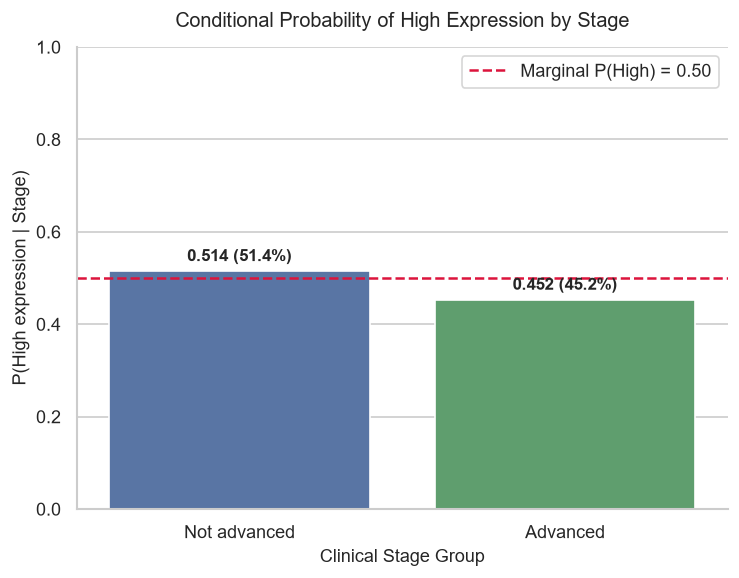

In [10]:
chi2, chi_p, dof, expected = stats.chi2_contingency(tab.values, correction=False)
print("Expected counts:\n", pd.DataFrame(expected, index=tab.index, columns=tab.columns))
fisher_or, fisher_p = stats.fisher_exact(tab.values)

# ریسک و نسبت ریسک
risk_high = p_A_given_B
risk_not_high = p_A_given_notB
rr = risk_high / risk_not_high if pd.notna(risk_high) and risk_not_high > 0 else np.nan

print(f"Chi-square={chi2:.4f}, df={dof}, p={chi_p:.6g}")
print(f"Fisher exact OR={fisher_or:.4f}, p={fisher_p:.6g}")
print(f"Risk(high)={risk_high:.4f}; Risk(not high)={risk_not_high:.4f}; RR={rr:.4f}")

# --- کد اصلاح‌شده و کامل‌تر برای رسم شکل ۲-۲ ---
fig, ax = plt.subplots(figsize=(7, 5))
prob_plot = pd.DataFrame({
    "Group": ["Not advanced", "Advanced"], 
    "P(high expression)": [p_B_given_notA, p_B_given_A]
})

# رسم میله‌ها با پالت یکدست
palette_colors = ["#4C72B0", "#55A868"]
bars = sns.barplot(
    data=prob_plot, 
    x="Group", 
    y="P(high expression)", 
    palette=palette_colors, 
    hue="Group", 
    legend=False, 
    ax=ax
)

# اضافه کردن خط افقی احتمال حاشیه‌ای کل P(High Expression) برای استناد مستقیم به مفهوم استقلال آماری
if 'p_B' in locals() or 'p_B' in globals():
    marginal_p = p_B
else:
    # در صورتی که تعریف نشده باشد، از ستون دوم جدول پیش‌آمدها استخراج می‌شود
    marginal_p = tab.iloc[:, 1].sum() / tab.values.sum()

ax.axhline(
    marginal_p, 
    color="crimson", 
    linestyle="--", 
    linewidth=1.5, 
    label=f"Marginal P(High) = {marginal_p:.2f}"
)

# نمایش درصدها بالای هر میله
for bar in ax.patches[:2]:
    height = bar.get_height()
    ax.annotate(
        f"{height:.3f} ({height*100:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

ax.set_ylim(0, 1.0)
ax.set_title("Conditional Probability of High Expression by Stage", fontsize=12, pad=12)
ax.set_ylabel("P(High expression | Stage)", fontsize=11)
ax.set_xlabel("Clinical Stage Group", fontsize=11)
ax.legend(loc="upper right", frameon=True)
sns.despine(top=True, right=True)

save_figure(fig, FIG / "conditional_probabilities.png")
plt.show()


## 3. Binomial distribution: explicit model-based simulation

Let \(X\) be the number of advanced-stage patients in a hypothetical independent sample of size \(n=20\), under an IID Bernoulli model with plug-in probability \(p=\widehat P(A)\). Then \(X\sim\operatorname{Binomial}(20,p)\), with \(E[X]=np\) and \(\operatorname{Var}(X)=np(1-p)\).

We simulate repeated samples **with replacement from the fitted Bernoulli model**. This is different from shuffling the observed cohort once and partitioning it into disjoint blocks, which creates dependent finite-population blocks and is not an IID binomial experiment. The simulation illustrates the fitted model; it does not establish that the cohort-generating mechanism is binomial.

Theoretical mean: 4.6200
Simulated mean: 4.6058
Theoretical variance: 3.5528
Simulated variance: 3.5558


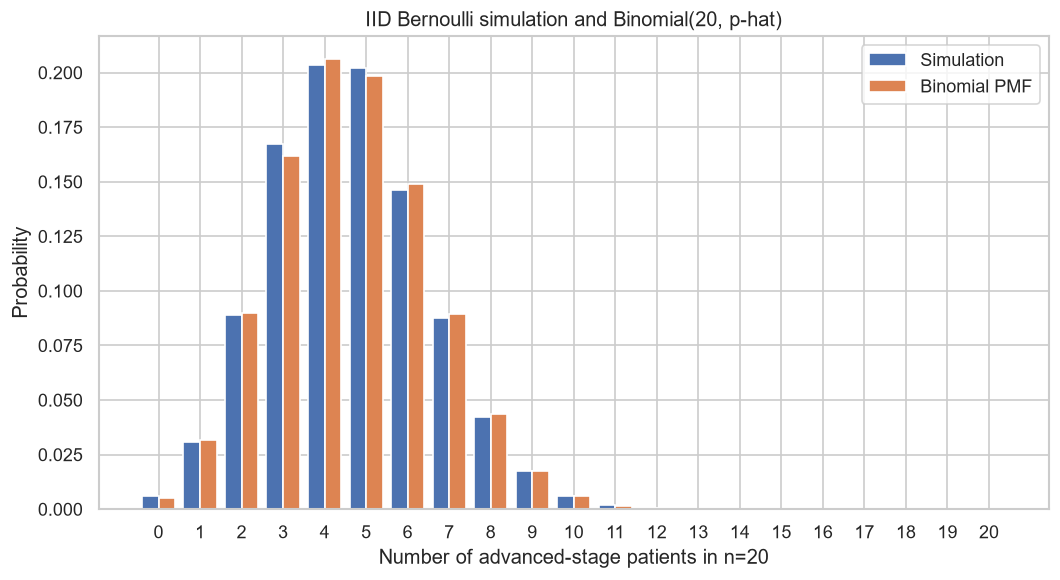

In [6]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

# Parameters
n = 20
num_simulations = 10000
p_hat = 0.2310 

# Simulate independent Binomial random variables
rng = np.random.default_rng(42)

simulated_counts = rng.binomial(
    n=n,
    p=p_hat,
    size=num_simulations
)

# Theoretical probabilities
x = np.arange(n + 1)
theoretical_pmf = binom.pmf(x, n, p_hat)

# Empirical probabilities
empirical_pmf = (
    np.bincount(simulated_counts, minlength=n + 1)
    / num_simulations
)

# Theoretical and simulated moments
theoretical_mean = n * p_hat
theoretical_variance = n * p_hat * (1 - p_hat)

simulated_mean = simulated_counts.mean()
simulated_variance = simulated_counts.var()

print(f"Theoretical mean: {theoretical_mean:.4f}")
print(f"Simulated mean: {simulated_mean:.4f}")

print(f"Theoretical variance: {theoretical_variance:.4f}")
print(f"Simulated variance: {simulated_variance:.4f}")

# Plot
fig, ax = plt.subplots(figsize=(9, 5))

width = 0.4

ax.bar(
    x - width / 2,
    empirical_pmf,
    width=width,
    label="Simulation"
)

ax.bar(
    x + width / 2,
    theoretical_pmf,
    width=width,
    label="Binomial PMF"
)

ax.set(
    xlabel="Number of advanced-stage patients in n=20",
    ylabel="Probability",
    title="IID Bernoulli simulation and Binomial(20, p-hat)"
)

ax.legend()
ax.set_xticks(x)
plt.tight_layout()

save_figure(fig, FIG / "binomial_comparison.png")
plt.show()


In [5]:
import numpy as np


# داده‌های اولیه
n_block = 20
n_blocks = 42
n_total_in_blocks = n_blocks * n_block
n_advanced = 194


# پارامترهای مدل
p = n_advanced / n_total_in_blocks
q = 1 - p


# محاسبات نظری
mean_theoretical = n_block * p
var_theoretical = n_block * p * q


# مقادیر تجربی گزارش شده
mean_empirical = 4.6190
var_empirical = 4.1928


print(f"--- تحلیل مدل دوجمله‌ای ---")
print(f"احتمال موفقیت (p): {p:.4f}")
print(f"میانگین نظری: {mean_theoretical:.4f} | میانگین تجربی: {mean_empirical:.4f}")
print(f"واریانس نظری: {var_theoretical:.4f} | واریانس تجربی: {var_empirical:.4f}")
print(f"Overdispersion Ratio (Var_emp / Var_theo): {var_empirical / var_theoretical:.4f}")

--- تحلیل مدل دوجمله‌ای ---
احتمال موفقیت (p): 0.2310
میانگین نظری: 4.6190 | میانگین تجربی: 4.6190
واریانس نظری: 3.5523 | واریانس تجربی: 4.1928
Overdispersion Ratio (Var_emp / Var_theo): 1.1803


## 4. Moments, spread, and normality of the molecular feature

We report mean, median, sample variance, sample standard deviation, skewness, excess kurtosis, quartiles, and IQR. The histogram and Q–Q plot are graphical diagnostics. A normality test is added, but its p-value must be interpreted with sample size in mind; it does not replace graphical and substantive assessment.

,Value
n,911.000000
mean,0.229056
median,0.197984
sample_variance,0.024788
sample_sd,0.157444
skewness,1.434093
excess_kurtosis,3.190429
Q1,0.118488
Q3,0.297562
IQR,0.179075


IQR-flagged expression values: 40


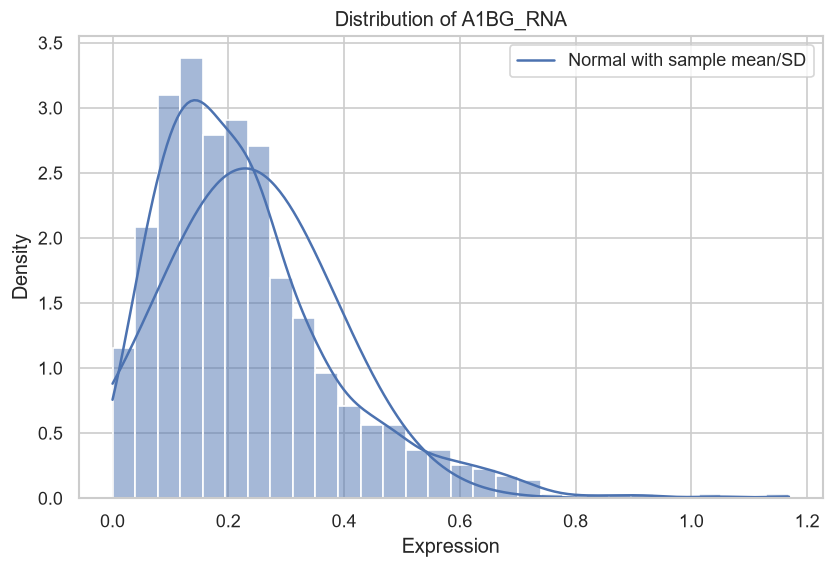

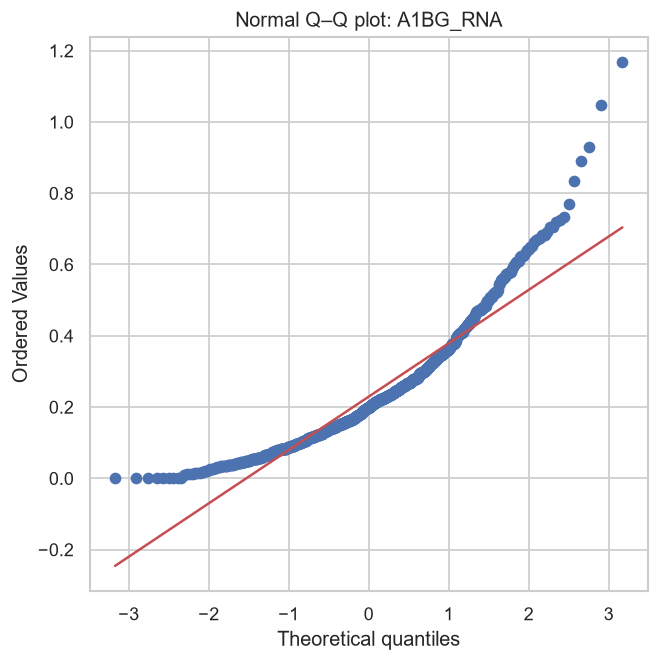

D’Agostino–Pearson K²=255.8041, p=2.83694e-56
Skewness before log: 1.43
Skewness after log: 0.98


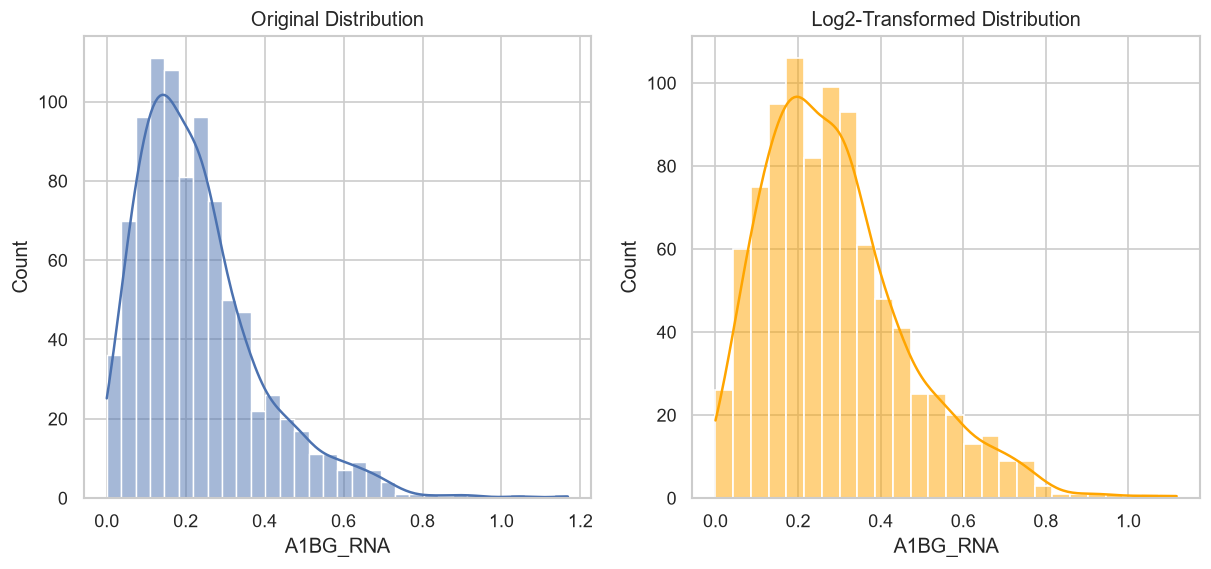

In [ ]:
x = analysis[SELECTED_GENE].dropna().astype(float)
summary = pd.Series({
    "n":x.size, "mean":x.mean(), "median":x.median(),
    "sample_variance":x.var(ddof=1), "sample_sd":x.std(ddof=1),
    "skewness":stats.skew(x, bias=False), "excess_kurtosis":stats.kurtosis(x, fisher=True, bias=False),
    "Q1":x.quantile(.25), "Q3":x.quantile(.75), "IQR":x.quantile(.75)-x.quantile(.25)
})
display(summary.to_frame("Value"))
q1,q3=x.quantile([.25,.75]); iqr=q3-q1
outliers=x[(x<q1-1.5*iqr)|(x>q3+1.5*iqr)]
print("IQR-flagged expression values:", len(outliers))

fig, ax = plt.subplots(figsize=(8,5))
sns.histplot(x, stat="density", bins=30, kde=True, ax=ax)
if x.std(ddof=1)>0:
    grid=np.linspace(x.min(),x.max(),300)
    ax.plot(grid, stats.norm.pdf(grid, loc=x.mean(), scale=x.std(ddof=1)), label="Normal with sample mean/SD")
    ax.legend()
ax.set(title=f"Distribution of {SELECTED_GENE}", xlabel="Expression", ylabel="Density")
save_figure(fig, FIG / "molecular_normality.png"); plt.show()

fig, ax = plt.subplots(figsize=(6,6))
stats.probplot(x, dist="norm", plot=ax)
ax.set_title(f"Normal Q–Q plot: {SELECTED_GENE}")
save_figure(fig, FIG / "molecular_qq_plot.png"); plt.show()

if 8 <= len(x) <= 5000:
    normal_stat, normal_p = stats.normaltest(x)
    print(f"D’Agostino–Pearson K²={normal_stat:.4f}, p={normal_p:.6g}")
elif len(x)>5000:
    print("Formal normality test omitted for n>5000; emphasize Q–Q plot, skewness and kurtosis.")
else:
    print("Sample too small for the selected omnibus normality test.")
    
# پیشنهاد: اضافه کردن یک تحلیل برای بررسی تاثیر Log Transformation
import numpy as np

# تبدیل لگاریتمی (Log2)
x_log = np.log2(x + 1) # اضافه کردن 1 برای جلوگیری از log(0)

# بررسی چولگی پس از تبدیل
print(f"Skewness before log: {stats.skew(x, bias=False):.2f}")
print(f"Skewness after log: {stats.skew(x_log, bias=False):.2f}")

# رسم مقایسه‌ای (اختیاری برای بهبود گزارش)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(x, kde=True, ax=ax[0])
ax[0].set_title("Original Distribution")
sns.histplot(x_log, kde=True, ax=ax[1], color="orange")
ax[1].set_title("Log2-Transformed Distribution")
plt.show()



## 5. Bivariate analysis: age and molecular expression

The covariance is reported in the original units and is scale-dependent. Pearson correlation measures linear association; Spearman correlation measures monotone association and is less sensitive to non-normal marginal distributions. Neither establishes causation.

### تحلیل همبستگی متغیرهای سن و بیان ژن $A1BG$
رابطه میان سن و بیان ژن $A1BG$ با استفاده از کوواریانس و ضریب همبستگی پیرسون مورد سنجش قرار گرفت. نتایج نشان‌دهنده یک همبستگی بسیار ضعیف و منفی ($r \approx -0.0127$) است که حاکی از فقدان رابطه خطی معنادار بین این دو متغیر در جمعیت مورد مطالعه می‌باشد. این یافته نشان می‌دهد که سطح بیان ژن $A1BG$ در این نمونه‌ها تابعِ خطیِ سن بیمار نیست.


Complete pairs: 936
Sample covariance: -0.0040456117002749085
Pearson r=-0.0020, p=0.952238
Spearman rho=0.0053, p=0.871745


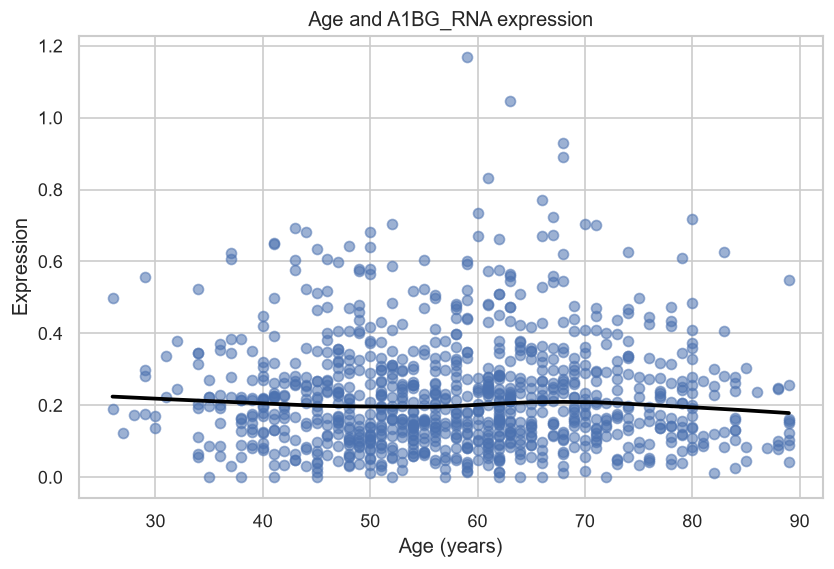

In [7]:
biv = df[["age_years", SELECTED_GENE]].dropna().copy()
if len(biv) < 3:
    raise ValueError("Insufficient complete pairs for bivariate analysis.")
covariance = biv.age_years.cov(biv[SELECTED_GENE])
pearson_r, pearson_p = stats.pearsonr(biv.age_years, biv[SELECTED_GENE])
spearman_r, spearman_p = stats.spearmanr(biv.age_years, biv[SELECTED_GENE])
print("Complete pairs:", len(biv))
print("Sample covariance:", covariance)
print(f"Pearson r={pearson_r:.4f}, p={pearson_p:.6g}")
print(f"Spearman rho={spearman_r:.4f}, p={spearman_p:.6g}")


fig, ax = plt.subplots(figsize=(8,5))
sns.regplot(data=biv, x="age_years", y=SELECTED_GENE, lowess=True, scatter_kws={"alpha":.55}, line_kws={"color":"black"}, ax=ax)
ax.set(title=f"Age and {SELECTED_GENE} expression", xlabel="Age (years)", ylabel="Expression")
save_figure(fig, FIG / "bivariate_covariance.png"); plt.show()

In [ ]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt



# بارگذاری داده‌ها (مطابق لیست فایل‌های موجود در Project.rar)
# از آنجایی که فایل اصلی clinical است، از آن استفاده می‌کنیم
try:
    df = pd.read_csv(r'E:\Uni\Statistics\Project\data\multiomics.csv')

    def analyze_variable(series, name):
        data = series.dropna()
        mean = data.mean()
        std = data.std()
        skew = stats.skew(data)
        kurt = stats.kurtosis(data)
        
        # شناسایی داده‌های پرت (IQR)
        Q1, Q3 = np.percentile(data, [25, 75])
        IQR = Q3 - Q1
        outliers = data[(data < (Q1 - 1.5 * IQR)) | (data > (Q3 + 1.5 * IQR))]
        
        print(f"--- تحلیل توزیع: {name} ---")
        print(f"میانگین: {mean:.4f} | انحراف معیار: {std:.4f}")
        print(f"چولگی: {skew:.4f} | کشیدگی: {kurt:.4f}")
        print(f"تعداد داده‌های پرت: {len(outliers)} ({len(outliers)/len(data)*100:.1f}%)")
        print("-" * 40)

    # تحلیل سن (موجود در فایل کلینیکی)
    if 'age_years' in df.columns:
        analyze_variable(df['age_years'], "Age")
    
    # تحلیل A1BG_RNA (اگر در فایل موجود باشد)
    if 'A1BG_RNA' in df.columns:
        analyze_variable(df['A1BG_RNA'], "A1BG_RNA")
    else:
        print("هشدار: ستون A1BG_RNA در فایل پیدا نشد. لطفاً نام دقیق ستون بیان ژن را بررسی کنید.")

except FileNotFoundError:
    print("خطا: فایل داده پیدا نشد. مسیر 'data/tcga_brca_clinical_core_aligned.csv' را چک کنید.")


Comparison for A1BG_RNA:
Early Stage Count: 690, Mean: 0.2342, Std: 0.1602
Advanced Stage Count: 221, Mean: 0.2129, Std: 0.1477
Welch's T-statistic: 1.8258, P-value: 0.0686


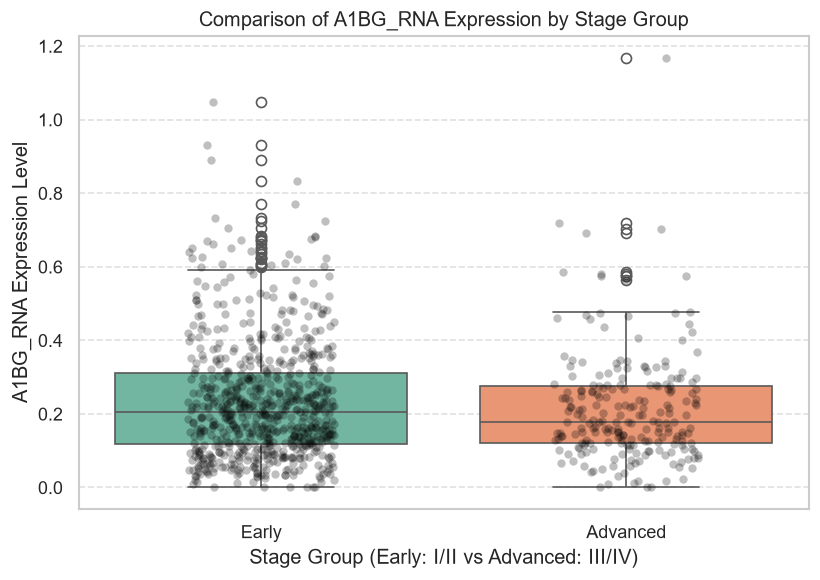

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

SELECTED_GENE = 'A1BG_RNA'

# ۱. حذف ردیف‌های نامعتبر/خالی و تفکیک بر اساس ستون stage_group
df_clean = df.dropna(subset=['stage_group', SELECTED_GENE])

early_expression = df_clean[df_clean['stage_group'] == 'Early'][SELECTED_GENE]
advanced_expression = df_clean[df_clean['stage_group'] == 'Advanced'][SELECTED_GENE]

# ۲. آزمون ولچ (Welch's t-test)
t_stat, p_val = stats.ttest_ind(early_expression, advanced_expression, equal_var=False)

print(f"Comparison for {SELECTED_GENE}:")
print(f"Early Stage Count: {len(early_expression)}, Mean: {early_expression.mean():.4f}, Std: {early_expression.std():.4f}")
print(f"Advanced Stage Count: {len(advanced_expression)}, Mean: {advanced_expression.mean():.4f}, Std: {advanced_expression.std():.4f}")
print(f"Welch's T-statistic: {t_stat:.4f}, P-value: {p_val:.4f}")

# ۳. رسم نمودار مقایسه‌ای
plt.figure(figsize=(7, 5))
sns.boxplot(
    x='stage_group',
    y=SELECTED_GENE,
    data=df_clean,
    hue='stage_group',
    legend=False,
    palette='Set2',
    order=['Early', 'Advanced']
)
sns.stripplot(x='stage_group', y=SELECTED_GENE, data=df_clean, color='black', alpha=0.25, jitter=0.2, order=['Early', 'Advanced'])

plt.title(f"Comparison of {SELECTED_GENE} Expression by Stage Group")
plt.xlabel("Stage Group (Early: I/II vs Advanced: III/IV)")
plt.ylabel(f"{SELECTED_GENE} Expression Level")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

# ذخیره در مسیر figures فاز ۲
plt.savefig(r'E:\Uni\Statistics\Project\figures\phase2\gene_selection_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## نتیجه مقایسه بیان ژن A1BG_RNA بر اساس گروه‌های بالینی (Stage Group)

- **گروه اولیه (Early - Stages I/II):** تعداد = ۶۹۰ | میانگین = ۰.۲۳۴۲ | انحراف معیار = ۰.۱۶۰۲
- **گروه پیشرفته (Advanced - Stages III/IV):** تعداد = ۲۲۱ | میانگین = ۰.۲۱۲۹ | انحراف معیار = ۰.۱۴۷۷
- **آزمون ولچ (Welch's t-test):** آماره $t = 1.8258$ ، مقدار $p = 0.0686$

**نتیجه‌گیری:** در سطح معناداری ۵٪ ($p > 0.05$)، تفاوت معناداری بین دو گروه بالینی مشاهده نمی‌شود؛ بنابراین $A1BG\_RNA$ به‌تنهایی توانایی تفکیک مرحله تومور را ندارد.


## 6. Phase 2 interpretation checklist

- Define \(A\), \(B\), the complete-case population, and the median threshold.
- State all probabilities from the same 2×2 contingency table and verify Bayes' identity numerically.
- Distinguish association from causation; report effect size alongside p-values.
- Explain that the Binomial calculation is an IID Bernoulli model-based simulation using \(\hat p\), not a claim that the fixed cohort is generated by independent draws.
- Interpret normality using histogram, Q–Q plot, skewness, kurtosis, and the test result together.
- Interpret covariance and correlations with their units/assumptions and avoid causal language.

### یافته‌های کلیدی فاز ۲
- **توزیع ژن:** $A1BG\_RNA$ دارای توزیع نامتقارن با چولگی مثبت است.
- **همبستگی:** عدم وجود همبستگی معنادار بین سن و بیان ژن ($p=0.95$).
- **تفکیک بالینی:** آزمون $t$ نشان داد که ژن $A1BG$ تفاوت معناداری در بیان بین مراحل اولیه و پیشرفته ندارد ($p=0.068$).
- **پیشنهاد:** تمرکز بر روی ترکیب چندین ژن (Signature-based approach) در فازهای بعدی.